# Did the New Shop Format Work? — Causal Impact of a Staggered Store Remodel
**Daily Data Analytics Project · Day 17**

## Business question
*A fuel-station network in Azerbaijan runs a convenience shop at each of its **60 stations** (Baku city, highways, regional towns). Since April 2025 it has remodelled **24 shops** to a new format (coffee bar, hot food, self-checkout) in three waves: April 2025, October 2025 and April 2026. Each remodel costs AZN 150–230k and closes the shop for two weeks. The board now has to approve wave 4 and asks: **how much extra revenue did the remodel really cause, does it differ by location, and which stations should be next?***

Why this is hard:
* The remodelled shops were **not chosen at random**: management picked the biggest shops first, so "remodelled vs not" compares big shops with small ones.
* Revenue moves for reasons that have nothing to do with the remodel: growth, New Year and Novruz peaks, a **fuel-price rise in January 2026**, and a strong **summer peak on highways** that Baku city shops don't have.
* Waves start at different dates and the effect **ramps up** over several weeks. A standard two-way fixed-effects regression is known to be biased in this setting.

Approach: naive comparisons → two-way fixed effects (TWFE) → **stratified difference-in-differences with never-remodelled controls** (Callaway–Sant'Anna style, written from scratch), event study and pre-trend checks, cluster bootstrap → **synthetic control** for the flagship drive-through station with placebo inference → ROI and payback per location type. Because the data is synthetic, every estimate is also checked against the **true effect** the generator used.

> Data is **synthetic** (fixed seed), generated by `data/generate_data.py`. Stations and the company are fictional.

In [1]:
import warnings; warnings.simplefilter("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import causal as c
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.edgecolor": "#898781", "axes.titleweight": "bold"})
pd.set_option("display.float_format", "{:,.3f}".format)
BLUE, ORANGE, RED, GREEN, GREY, PURPLE = "#2a78d6", "#eb6834", "#d03b3b", "#1baf7a", "#898781", "#7a5cc7"
TCOL = {"Baku city": BLUE, "Highway": ORANGE, "Regional town": GREEN}
sales_raw, st = c.load_raw()
print(sales_raw.shape, st.shape); sales_raw.head()

(8948, 4) (60, 7)


,station_id,week_start,revenue_azn,transactions
0,ST-07,2025-06-16,"21,980.620",1841
1,ST-24,2024-01-15,"13,245.050",1145
2,ST-01,2025-12-29,"12,000.240",1049
3,ST-54,2026-05-18,"8,227.790",878
4,ST-33,2025-07-14,"19,650.510",1360


## 1. Data quality check

In [2]:
p, log = c.clean(sales_raw, st)
weeks = pd.date_range(p.week_start.min(), p.week_start.max(), freq="W-MON")
checks = {**log, "station-weeks after cleaning": len(p), "stations / weeks": f"{p.station_id.nunique()} / {len(weeks)}",
          "date range": f"{weeks.min():%Y-%m-%d} → {weeks.max():%Y-%m-%d}",
          "stations in sales but not in master": len(set(p.station_id) - set(st.station_id))}
pd.Series(checks).to_frame("result")

,result
raw rows,8948
station codes normalised,371
duplicate rows dropped,180
revenue rows in qəpik (÷100),40
zero-revenue weeks,48
…of which match the remodel log (construction),48
missing station-weeks (feed gaps),112
station-weeks after cleaning,8768
stations / weeks,60 / 148
date range,2024-01-01 → 2026-10-26


Fixes: station codes typed as `st-07`, `ST07` or ` ST-07 ` are normalised to `ST-07`. 180 rows from a double upload are dropped. 40 weeks arrived in **qəpik** (an implied basket ~100× the station's normal one) and are divided by 100. All 48 zero-revenue weeks are the two construction weeks before each reopening in the remodel log. They are kept out of the estimation, because a closed shop is not the "before" state. The 112 station-weeks missing because of feed gaps are left missing; every estimator below handles gaps.

In [3]:
st["cohort"] = st.remodel_date.dt.strftime("%b %Y").fillna("never")
pd.crosstab(st.location_type, st.cohort, margins=True)[["Apr 2025", "Oct 2025", "Apr 2026", "never", "All"]]

cohort,Apr 2025,Oct 2025,Apr 2026,never,All
location_type,,,,,
Baku city,2,3,3,22,30
Highway,4,3,3,5,15
Regional town,2,2,2,9,15
All,8,8,8,36,60


## 2. KPIs

In [4]:
pre = p[(p.week_start < "2025-03-24") & ~p.closed]
lvl = pre.groupby("station_id").revenue_azn.mean().rename("pre_weekly_rev").to_frame().join(st.set_index("station_id")[["location_type", "cohort"]])
lvl["remodelled"] = np.where(lvl.cohort == "never", "never remodelled", "remodelled")
last52 = p[p.week_start > p.week_start.max() - pd.Timedelta(weeks=52)]
k = {"Network shop revenue, last 52 weeks (AZN M)": last52.revenue_azn.sum() / 1e6,
     "Avg weekly revenue per shop, last 52 w (AZN)": last52.groupby("station_id").revenue_azn.mean().mean(),
     "Avg basket, last 52 w (AZN)": last52.revenue_azn.sum() / last52.transactions.sum(),
     "Remodel capex to date (AZN M)": st.remodel_capex_azn.sum() / 1e6,
     "Pre-2025 weekly revenue: remodelled shops (AZN)": lvl.query("remodelled=='remodelled'").pre_weekly_rev.mean(),
     "Pre-2025 weekly revenue: never-remodelled shops (AZN)": lvl.query("remodelled!='remodelled'").pre_weekly_rev.mean()}
pd.Series(k).to_frame("value")

,value
"Network shop revenue, last 52 weeks (AZN M)",65.044
"Avg weekly revenue per shop, last 52 w (AZN)","21,224.961"
"Avg basket, last 52 w (AZN)",12.176
Remodel capex to date (AZN M),4.642
Pre-2025 weekly revenue: remodelled shops (AZN),"23,502.135"
Pre-2025 weekly revenue: never-remodelled shops (AZN),"16,426.564"


In [5]:
lvl.groupby(["location_type", "remodelled"]).pre_weekly_rev.agg(["count", "mean"]).unstack()

count                        mean           
remodelled    never remodelled remodelled never remodelled remodelled
location_type                                                        
Baku city                   22          8       16,338.128 21,826.795
Highway                      5         10       26,170.371 29,230.970
Regional town                9          6       11,229.514 16,187.864

Before any remodel took place, remodelled shops already sold **more** than the rest, in every location type. Management picked big shops first. Any comparison of remodelled and other shops *after* the remodel mixes this head start into the effect.

## 3. EDA

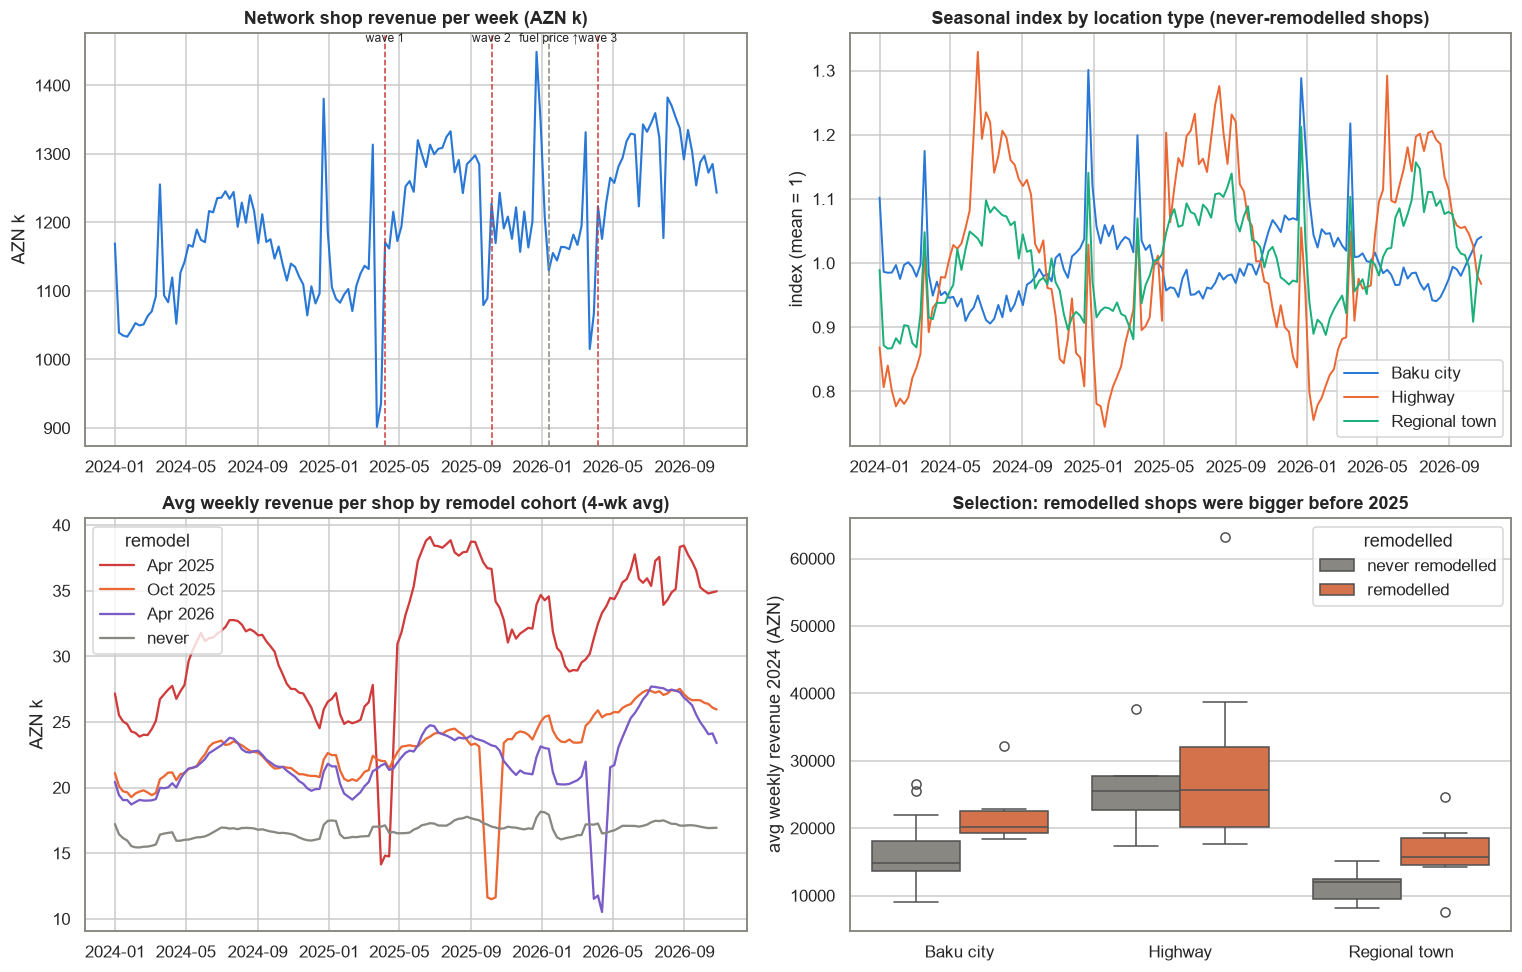

In [6]:
fig, ax = plt.subplots(2, 2, figsize=(14, 9))
net = p.groupby("week_start").revenue_azn.sum() / 1e3
ax[0, 0].plot(net.index, net.values, color=BLUE, lw=1.4)
for d, lab in [("2025-04-07", "wave 1"), ("2025-10-06", "wave 2"), ("2026-04-06", "wave 3"), ("2026-01-12", "fuel price ↑")]:
    ax[0, 0].axvline(pd.Timestamp(d), color=RED if "wave" in lab else GREY, ls="--", lw=1)
    ax[0, 0].text(pd.Timestamp(d), net.max() * 1.01, lab, fontsize=8, ha="center")
ax[0, 0].set(title="Network shop revenue per week (AZN k)", ylabel="AZN k")
# seasonality by location type, never-remodelled shops only, 2024
nv = p[p.remodel_date.isna()]
idx = nv.groupby(["location_type", "week_start"]).log_rev.mean().unstack(0)
idx = np.exp(idx - idx.mean())
for t in c.TYPES:
    ax[0, 1].plot(idx.index, idx[t], label=t, color=TCOL[t], lw=1.3)
ax[0, 1].set(title="Seasonal index by location type (never-remodelled shops)", ylabel="index (mean = 1)"); ax[0, 1].legend()
# raw cohort lines
p["cohort"] = p.station_id.map(st.set_index("station_id").cohort)
cl = p.groupby(["cohort", "week_start"]).revenue_azn.mean().unstack(0) / 1e3
for coh, col in [("Apr 2025", RED), ("Oct 2025", ORANGE), ("Apr 2026", PURPLE), ("never", GREY)]:
    ax[1, 0].plot(cl.index, cl[coh].rolling(4, min_periods=1).mean(), label=coh, color=col, lw=1.5)
ax[1, 0].set(title="Avg weekly revenue per shop by remodel cohort (4-wk avg)", ylabel="AZN k"); ax[1, 0].legend(title="remodel")
sns.boxplot(data=lvl.reset_index(), x="location_type", y="pre_weekly_rev", hue="remodelled", ax=ax[1, 1],
            palette={"remodelled": ORANGE, "never remodelled": GREY}, order=c.TYPES)
ax[1, 1].set(title="Selection: remodelled shops were bigger before 2025", xlabel="", ylabel="avg weekly revenue 2024 (AZN)")
plt.tight_layout(); plt.savefig("images/eda_overview.png", dpi=120, bbox_inches="tight"); plt.show()

* Network revenue has a sharp New Year spike, a Novruz bump in March and a step down after the January 2026 fuel-price rise.
* **Highway shops have a summer peak of about ±20%. Baku city shops dip slightly in summer**, when residents leave the city. A control group made mostly of city shops therefore gives a wrong counterfactual for a highway shop.
* The wave-1 cohort (red) is the biggest and pulls away after April 2025, but it was already ahead before that.

## 4. Naive estimates (what a quick dashboard would say)
All effects are in **log points** (0.10 ≈ +10.5% revenue).

In [7]:
Y = c.wide(p); rel = c.rel_week_matrix(Y, st)
gt = pd.read_csv("data/ground_truth.csv", parse_dates=["week_start"]).pivot(index="station_id", columns="week_start", values="true_log_effect").loc[Y.index]
R, Yv, G = rel.to_numpy(), Y.to_numpy(), gt.to_numpy()
TRUE_ATT = np.nanmean(np.where(R >= 0, G, np.nan))
# (a) before/after on remodelled shops: 26 weeks after vs 26 weeks before construction
ba = np.nanmean(np.where((R >= 0) & (R < 26), Yv, np.nan), 1) - np.nanmean(np.where((R >= -28) & (R < -2), Yv, np.nan), 1)
true_ba = np.nanmean(np.where((R >= 0) & (R < 26), G, np.nan), 1)
# (b) remodelled vs never remodelled, all weeks after 7 Apr 2025
post = Y.columns >= "2025-04-07"
treat_now = (R >= 0)
cross = np.nanmean(np.where(treat_now[:, post], Yv[:, post], np.nan)) - np.nanmean(Yv[st.set_index("station_id").loc[Y.index].remodel_date.isna().to_numpy()][:, post])
est = pd.DataFrame({"estimate": [np.nanmean(ba), cross], "truth": [np.nanmean(true_ba), TRUE_ATT]},
                   index=["Before/after (26 w), remodelled shops", "Remodelled vs never-remodelled, after Apr 2025"])
est

,estimate,truth
"Before/after (26 w), remodelled shops",0.139,0.094
"Remodelled vs never-remodelled, after Apr 2025",0.498,0.109


Both quick answers are wrong. **Before/after** picks up seasonality and growth: a wave-1 highway shop goes from spring into its summer peak, and a wave-2 shop goes from autumn into winter. **Remodelled vs not** mostly measures how much bigger the chosen shops were to begin with. It over-states the effect several times.

## 5. Two-way fixed effects (TWFE)
`log_rev ~ station FE + week FE + D(remodelled & after go-live)`, with standard errors clustered by station (sandwich estimator written in NumPy). Station fixed effects remove the size difference; week fixed effects remove common shocks.

In [8]:
tw = c.twfe(p); tw2 = c.twfe(p, "type_week")
twfe_tab = pd.DataFrame({"estimate": [tw[0], tw2[0]], "cluster SE": [tw[1], tw2[1]]},
                        index=["TWFE: station FE + week FE", "TWFE: station FE + location-type × week FE"])
twfe_tab["truth"] = TRUE_ATT; twfe_tab

,estimate,cluster SE,truth
TWFE: station FE + week FE,0.122,0.018,0.109
TWFE: station FE + location-type × week FE,0.096,0.013,0.109


TWFE removes the selection on size, but two problems remain:
1. With plain week effects, highway shops (most of wave 1) are compared with a mostly-city control group that has the **opposite seasonal pattern**. The estimate depends on which months happen to be in the post-period.
2. With location-type × week effects the seasonality is fixed, but the estimate falls **below** the truth. With staggered adoption, TWFE also uses *already-remodelled* shops as controls for later waves. Their effect is still growing during the ramp-up, so that growth is subtracted from the later waves' effect (the Goodman-Bacon "forbidden comparisons").

## 6. Stratified difference-in-differences (Callaway–Sant'Anna style)
For each remodelled shop *i* and week *t*: effect = (y<sub>it</sub> − its baseline) − average over **never-remodelled shops of the same location type** of (y<sub>jt</sub> − their baseline). The baseline is the mean of weeks −10…−3 before the cohort's go-live (construction weeks −2, −1 excluded). Only clean controls are used, and each location type gets its own seasonal counterfactual. Uncertainty comes from a **cluster bootstrap**: 400 resamples of stations within cohort × type cells.

In [9]:
E_MIN, E_MAX = -40, 70
def stats(Yb, sb):
    tau = c.unit_effects(Yb, sb); rl = c.rel_week_matrix(Yb, sb)
    s = sb.set_index("station_id").loc[Yb.index]
    T, Rm = tau.to_numpy(), rl.to_numpy()
    out = [c.overall_att(tau, rl)]
    for typ in c.TYPES:
        m = ((s.location_type == typ) & (s.format == "new")).to_numpy()
        out.append(np.nanmean(np.where((Rm[m] >= 20), T[m], np.nan)))
    es = c.event_study(tau, rl, E_MIN, E_MAX).reindex(range(E_MIN, E_MAX + 1))
    lead = np.nanmean(np.where((Rm >= -30) & (Rm <= -3), T, np.nan))
    return np.concatenate([out, [lead], es.to_numpy()])
point = stats(Y, st)
boot = c.cluster_bootstrap(Y, st, stats, B=400, seed=17)
se = np.nanstd(boot, axis=0)
lo, hi = np.nanpercentile(boot, 2.5, axis=0), np.nanpercentile(boot, 97.5, axis=0)
tau_hat = c.unit_effects(Y, st); tau_uns = c.unit_effects(Y, st, stratify=False)
ATT, ATT_SE = point[0], se[0]
print(f"Overall ATT = {ATT:.3f}  (95% CI {lo[0]:.3f} – {hi[0]:.3f}),  truth = {TRUE_ATT:.3f}")
print(f"Pre-period placebo (avg of weeks −30…−3) = {point[4]:.4f}  (95% CI {lo[4]:.3f} – {hi[4]:.3f})")
print(f"Unstratified (all never-remodelled as controls) ATT = {c.overall_att(tau_uns, rel):.3f}")

Overall ATT = 0.119  (95% CI 0.098 – 0.141),  truth = 0.109
Pre-period placebo (avg of weeks −30…−3) = 0.0093  (95% CI -0.004 – 0.023)
Unstratified (all never-remodelled as controls) ATT = 0.154


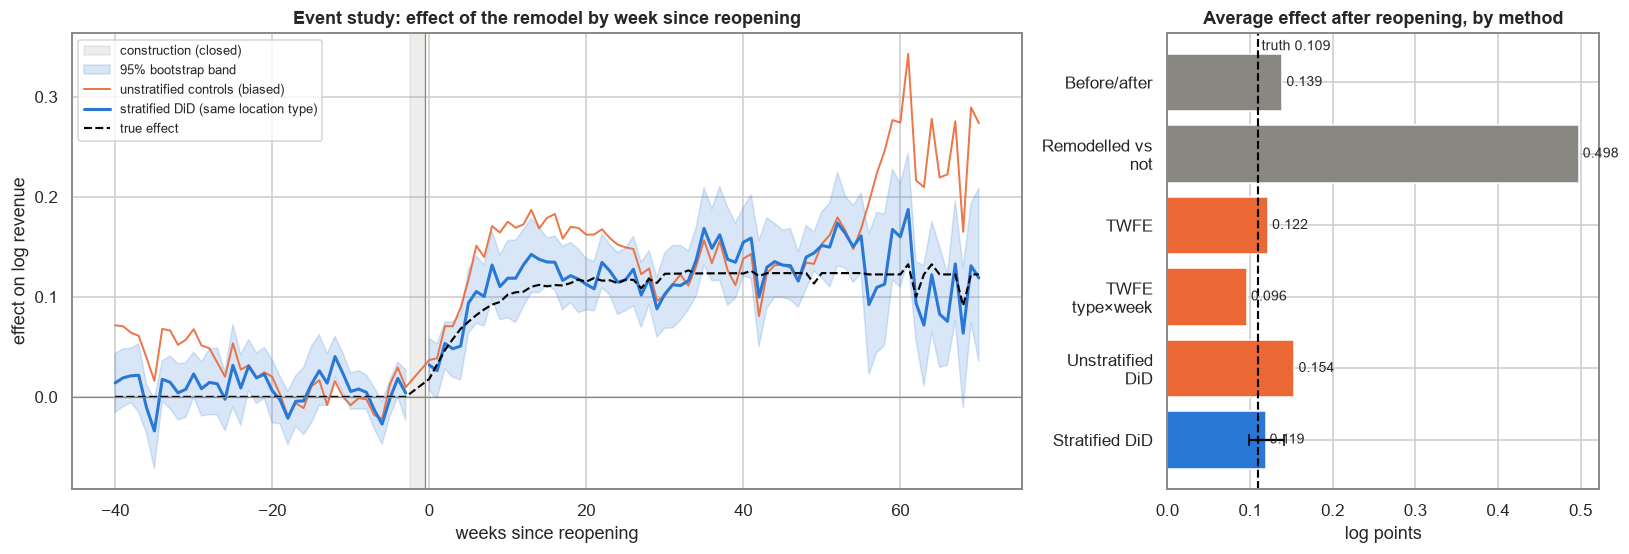

In [10]:
es_s = pd.Series(point[5:], index=range(E_MIN, E_MAX + 1)); es_lo = pd.Series(lo[5:], index=es_s.index); es_hi = pd.Series(hi[5:], index=es_s.index)
es_u = c.event_study(tau_uns, rel, E_MIN, E_MAX)
es_true = c.event_study(gt.where(~np.isnan(tau_hat)), rel, E_MIN, E_MAX)
fig, ax = plt.subplots(1, 2, figsize=(15, 5.2), gridspec_kw={"width_ratios": [2.2, 1]})
ax[0].axvspan(-2.5, -0.5, color=GREY, alpha=.15, label="construction (closed)")
ax[0].fill_between(es_s.index, es_lo, es_hi, color=BLUE, alpha=.18, label="95% bootstrap band")
ax[0].plot(es_u.index, es_u.values, color=ORANGE, lw=1.3, alpha=.9, label="unstratified controls (biased)")
ax[0].plot(es_s.index, es_s.values, color=BLUE, lw=2, label="stratified DiD (same location type)")
ax[0].plot(es_true.index, es_true.values, color="black", ls="--", lw=1.4, label="true effect")
ax[0].axhline(0, color=GREY, lw=.8); ax[0].axvline(-0.5, color=GREY, lw=.8)
ax[0].set(title="Event study: effect of the remodel by week since reopening", xlabel="weeks since reopening", ylabel="effect on log revenue")
ax[0].legend(loc="upper left", fontsize=8.5)
labels = ["Before/after", "Remodelled vs\nnot", "TWFE", "TWFE\ntype×week", "Unstratified\nDiD", "Stratified DiD"]
vals = [est.estimate.iloc[0], est.estimate.iloc[1], tw[0], tw2[0], c.overall_att(tau_uns, rel), ATT]
cols = [GREY, GREY, ORANGE, ORANGE, ORANGE, BLUE]
ax[1].barh(labels[::-1], vals[::-1], color=cols[::-1])
ax[1].errorbar(ATT, 0, xerr=[[ATT - lo[0]], [hi[0] - ATT]], color="black", capsize=4)
ax[1].axvline(TRUE_ATT, color="black", ls="--", lw=1.4); ax[1].text(TRUE_ATT, 5.45, f" truth {TRUE_ATT:.3f}", fontsize=9)
for i, v in enumerate(vals[::-1]): ax[1].text(v + .005, i, f"{v:.3f}", va="center", fontsize=9)
ax[1].set(title="Average effect after reopening, by method", xlabel="log points")
plt.tight_layout(); plt.savefig("images/event_study.png", dpi=120, bbox_inches="tight"); plt.show()

* **Pre-trends:** before construction the stratified estimate stays flat around zero. The average placebo effect over weeks −30…−3 is close to zero and its confidence interval includes zero, so the parallel-trends assumption holds *within* location type. With unstratified controls (orange) the pre-period moves with the seasons: that is the highway summer peak leaking into the estimate.
* **Dynamics:** the effect is not a step. It builds over roughly the first 10–15 weeks (new customers find the coffee bar and hot food) and then levels off. A test read after 4 weeks would under-state it by about half.
* **Method comparison:** only the stratified DiD lands on the true effect within its confidence interval. The naive comparisons are off several times. TWFE with type × week effects is biased **down**, because of the ramp-up and staggered timing.

### 6b. Where does the extra revenue come from — more customers or bigger baskets?

In [11]:
p["log_trx"] = np.log(p.transactions.where(p.transactions > 0)); p.loc[p.closed, "log_trx"] = np.nan
p["log_basket"] = p.log_rev - p.log_trx
dec = {}
for col in ["log_rev", "log_trx", "log_basket"]:
    W = c.wide(p, col); t_ = c.unit_effects(W, st); dec[col] = c.overall_att(t_, c.rel_week_matrix(W, st))
dec = pd.Series(dec).rename({"log_rev": "revenue", "log_trx": "transactions", "log_basket": "avg basket"}).to_frame("ATT (log points)")
dec["share of revenue effect"] = dec.iloc[:, 0] / dec.iloc[0, 0]; dec

,ATT (log points),share of revenue effect
revenue,0.119,1.000
transactions,0.078,0.653
avg basket,0.041,0.347


About **two thirds** of the uplift comes from **more transactions** and one third from a **bigger basket**. The new format brings in new customers (coffee, food), not only bigger tickets from the same fuel customers.

## 7. Heterogeneity: location type and cohort
Steady-state effect = average effect from week 20 after reopening onward. The flagship drive-through (ST-45) is excluded here and analysed separately in §8.

In [12]:
het = pd.DataFrame({"steady-state effect": point[1:4], "95% CI low": lo[1:4], "95% CI high": hi[1:4]}, index=c.TYPES)
s_ = st.set_index("station_id").loc[Y.index]
het["true effect"] = [np.nanmean(np.where((R[m] >= 20) & ~np.isnan(tau_hat.to_numpy()[m]), G[m], np.nan))
                      for m in [((s_.location_type == t) & (s_.format == "new")).to_numpy() for t in c.TYPES]]
het["uplift %"] = (np.exp(het["steady-state effect"]) - 1) * 100
het["shops"] = [int(((s_.location_type == t) & (s_.format == "new")).sum()) for t in c.TYPES]
het

,steady-state effect,95% CI low,95% CI high,true effect,uplift %,shops
Baku city,0.064,0.040,0.085,0.054,6.621,8
Highway,0.176,0.148,0.212,0.159,19.221,9
Regional town,0.083,0.060,0.107,0.102,8.605,6


In [13]:
coh_tab = {}
T_ = tau_hat.to_numpy()
for coh in ["Apr 2025", "Oct 2025", "Apr 2026"]:
    m = (s_.cohort == coh).to_numpy()
    coh_tab[coh] = {"shops": int(m.sum()), "weeks observed after reopening": int(np.nanmax(R[m])) + 1,
                    "ATT weeks 0–25": np.nanmean(np.where((R[m] >= 0) & (R[m] < 26), T_[m], np.nan)),
                    "truth weeks 0–25": np.nanmean(np.where((R[m] >= 0) & (R[m] < 26), G[m], np.nan))}
pd.DataFrame(coh_tab).T

,shops,weeks observed after reopening,ATT weeks 0–25,truth weeks 0–25
Apr 2025,8.000,82.000,0.120,0.097
Oct 2025,8.000,56.000,0.129,0.099
Apr 2026,8.000,30.000,0.068,0.086


The remodel works best on **highways** (about +19%, truth +17%), well ahead of **regional towns** (about +9%) and **Baku city** (about +7%). City shops compete with many corner shops and cafés, while a highway driver has nowhere else to stop. All three confidence intervals contain the true effect.

By cohort, waves 1 and 2 give very similar first-26-week effects. Wave 3 (April 2026) comes out lower (0.068 vs a true 0.086). With 8 shops per cohort, a cohort estimate moves by about ±0.03, so this gap is within noise and does not show that the format is wearing off. Wave 3 should be re-read once it has 52 weeks of data.

## 8. Synthetic control: the flagship drive-through (ST-45, Baku–Quba M1)
ST-45 got the new format **plus a drive-through lane** (AZN 90k extra). With a single unit, the station is compared with a **weighted combination of never-remodelled shops** whose pre-period path matches it. The variant used is demeaned synthetic control: weights ≥ 0 that sum to 1, fitted to deviations from each shop's own mean, so a level difference is allowed. For inference, each donor shop is treated as a placebo in turn, and the post/pre RMSPE ratio of ST-45 is ranked against the placebos.

In [14]:
FL = "ST-45"; g = st.set_index("station_id").loc[FL, "remodel_date"]
donors = st[st.remodel_date.isna()].station_id.tolist()
wk = Y.columns; pre_mask = np.asarray(wk < g - pd.Timedelta(weeks=2)); post_mask = np.asarray(wk >= g)
w, synth = c.synth_path(Y, FL, donors, pre_mask)
gap = Y.loc[FL].to_numpy() - synth
ratio_fl = c.rmspe(gap, post_mask) / c.rmspe(gap, pre_mask)
plac = {}
for d in donors:
    others = [x for x in donors if x != d]
    _, sy = c.synth_path(Y, d, others, pre_mask)
    gp = Y.loc[d].to_numpy() - sy
    plac[d] = (gp, c.rmspe(gp, post_mask) / c.rmspe(gp, pre_mask))
ratios = np.array([v[1] for v in plac.values()])
p_val = (1 + (ratios >= ratio_fl).sum()) / (1 + len(ratios))
fl_eff = np.nanmean(gap[(R[list(Y.index).index(FL)] >= 20)])
fl_true = np.nanmean(G[list(Y.index).index(FL)][R[list(Y.index).index(FL)] >= 20])
wt = pd.Series(w, index=donors).sort_values(ascending=False)
wt = wt[wt > 0.01].to_frame("weight").join(st.set_index("station_id")[["location_type", "area"]])
print(f"Pre-period RMSPE {c.rmspe(gap, pre_mask):.3f} | steady-state effect (wk 20+) {fl_eff:.3f} = +{(np.exp(fl_eff)-1)*100:.0f}%  (truth {fl_true:.3f})")
print(f"RMSPE ratio rank: {int((ratios >= ratio_fl).sum()) + 1} of {len(ratios) + 1}  →  permutation p = {p_val:.3f}")
wt

Pre-period RMSPE 0.060 | steady-state effect (wk 20+) 0.272 = +31%  (truth 0.279)
RMSPE ratio rank: 1 of 37  →  permutation p = 0.027


,weight,location_type,area
ST-31,0.424,Highway,Baku-Alat M3
ST-33,0.282,Highway,Ganja-Gazakh M2
ST-34,0.148,Highway,Baku-Alat M3
ST-36,0.126,Highway,Ganja-Gazakh M2
ST-59,0.017,Regional town,Shirvan


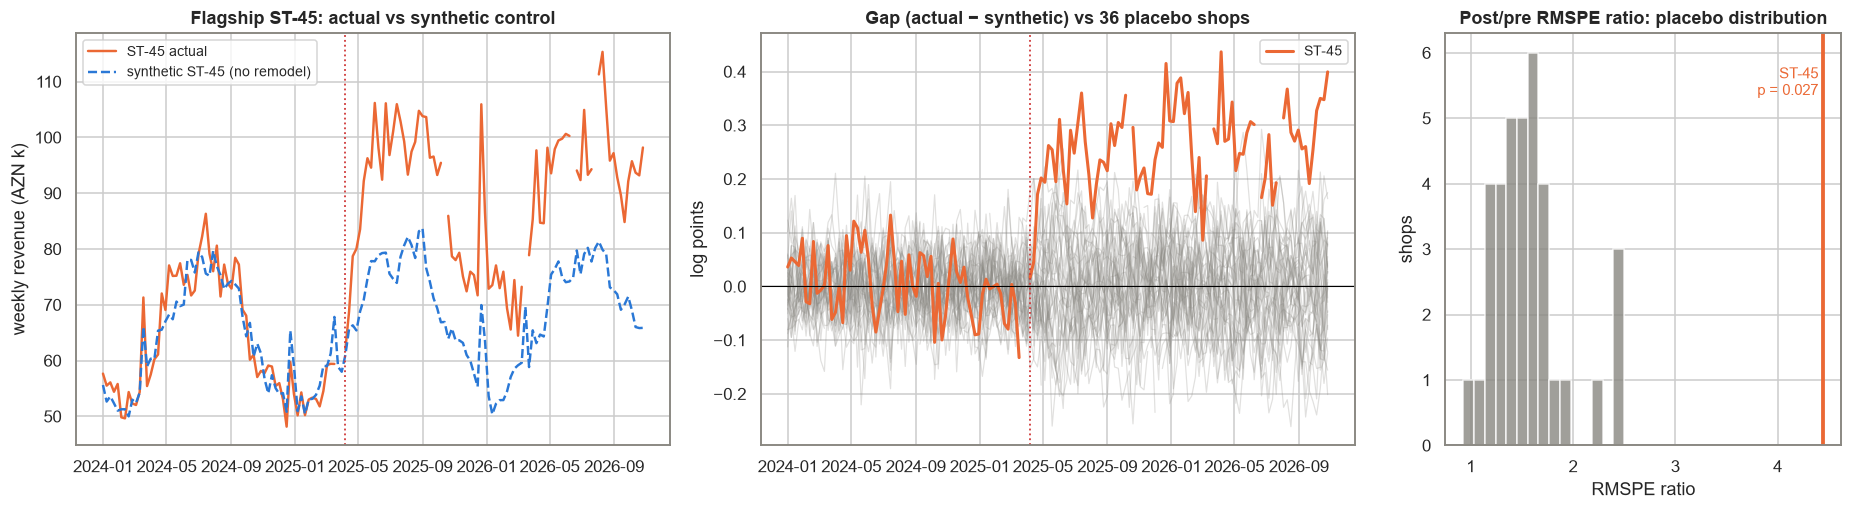

In [15]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8), gridspec_kw={"width_ratios": [1.5, 1.5, 1]})
ax[0].plot(wk, np.exp(Y.loc[FL]) / 1e3, color=ORANGE, lw=1.6, label="ST-45 actual")
ax[0].plot(wk, np.exp(synth) / 1e3, color=BLUE, lw=1.6, ls="--", label="synthetic ST-45 (no remodel)")
ax[0].axvline(g, color=RED, ls=":", lw=1.2); ax[0].set(title="Flagship ST-45: actual vs synthetic control", ylabel="weekly revenue (AZN k)"); ax[0].legend(fontsize=9)
for d, (gp, _) in plac.items(): ax[1].plot(wk, gp, color=GREY, alpha=.25, lw=.8)
ax[1].plot(wk, gap, color=ORANGE, lw=2, label="ST-45"); ax[1].axvline(g, color=RED, ls=":", lw=1.2); ax[1].axhline(0, color="black", lw=.7)
ax[1].set(title="Gap (actual − synthetic) vs 36 placebo shops", ylabel="log points"); ax[1].legend(fontsize=9)
ax[2].hist(ratios, bins=15, color=GREY, alpha=.8); ax[2].axvline(ratio_fl, color=ORANGE, lw=2.5)
ax[2].text(ratio_fl - .05, ax[2].get_ylim()[1] * .85, f"ST-45\np = {p_val:.3f}", color=ORANGE, fontsize=10, ha="right")
ax[2].set(title="Post/pre RMSPE ratio: placebo distribution", xlabel="RMSPE ratio", ylabel="shops")
plt.tight_layout(); plt.savefig("images/synthetic_control.png", dpi=120, bbox_inches="tight"); plt.show()

The synthetic ST-45 is built mainly from the never-remodelled **highway** shops and (weights in the table above) and tracks the real station closely for the 15 months before construction, including the 2024 summer peak (pre-period RMSPE 0.06). After reopening, the gap levels off at about **+31%** (true effect: +32%), about twice the uplift of a normal highway remodel. **No placebo shop comes close**: ST-45 has the most extreme RMSPE ratio of all 37 shops, which is the smallest p-value this test can give.

## 9. ROI and payback
* Incremental revenue per shop-week = actual × (1 − e<sup>−effect</sup>), using each shop's own estimated effect.
* Incremental gross margin: **35%** of incremental sales (coffee and hot food carry a higher margin than the 28% shop average). The two closed weeks cost 28% margin on the shop's baseline revenue.
* Steady-state annual gain = steady-state effect (week 20+) × each shop's counterfactual revenue × 52. NPV over 5 years at a 12% discount rate. Capex comes from the remodel log.

In [16]:
GM_INC, GM_BASE, R_DISC, YEARS = 0.35, 0.28, 0.12, 5
rev = c.wide(p, "revenue_azn").loc[Y.index].to_numpy()
inc = np.where(R >= 0, rev * (1 - np.exp(-tau_hat.to_numpy())), np.nan)
inc_true = np.where((R >= 0) & ~np.isnan(tau_hat.to_numpy()), rev * (1 - np.exp(-G)), np.nan)
print(f"Incremental revenue to date, all 24 remodelled shops: AZN {np.nansum(inc)/1e6:.2f} M (truth AZN {np.nansum(inc_true)/1e6:.2f} M)")
rows = []
for i, sid in enumerate(Y.index):
    s = s_.loc[sid]
    if pd.isna(s.remodel_date): continue
    pre_rev = np.nanmean(np.where((R[i] >= -28) & (R[i] < -2), rev[i], np.nan))
    cf = np.nanmean(np.where(R[i] >= 0, rev[i] * np.exp(-T_[i]), np.nan))           # counterfactual weekly revenue
    eff = fl_eff if sid == FL else het.loc[s.location_type, "steady-state effect"]
    gain = cf * (np.exp(eff) - 1) * 52 * GM_INC
    closure = 2 * pre_rev * GM_BASE
    npv = -s.remodel_capex_azn - closure + sum(gain / (1 + R_DISC) ** y for y in range(1, YEARS + 1))
    rows.append({"station": sid, "type": "Flagship drive-through" if sid == FL else s.location_type, "capex": s.remodel_capex_azn,
                 "annual GM gain": gain, "payback (years)": (s.remodel_capex_azn + closure) / gain, "5-yr NPV": npv})
roi = pd.DataFrame(rows)
roi_t = roi.groupby("type").agg(shops=("station", "size"), capex=("capex", "mean"), annual_gm_gain=("annual GM gain", "mean"),
                                payback_years=("payback (years)", "median"), npv_5y=("5-yr NPV", "mean"), npv_positive=("5-yr NPV", lambda x: f"{(x > 0).sum()}/{len(x)}"))
roi_t.round(1)

Incremental revenue to date, all 24 remodelled shops: AZN 5.50 M (truth AZN 4.89 M)


,shops,capex,annual_gm_gain,payback_years,npv_5y,npv_positive
type,,,,,,
Baku city,8,"185,625.000","26,727.700",7.500,"-102,047.600",0/8
Flagship drive-through,1,"309,000.000","376,653.300",0.900,"1,017,002.000",1/1
Highway,9,"219,111.100","96,693.900",2.600,"114,911.000",9/9
Regional town,6,"146,000.000","27,510.800",6.100,"-56,246.500",0/6


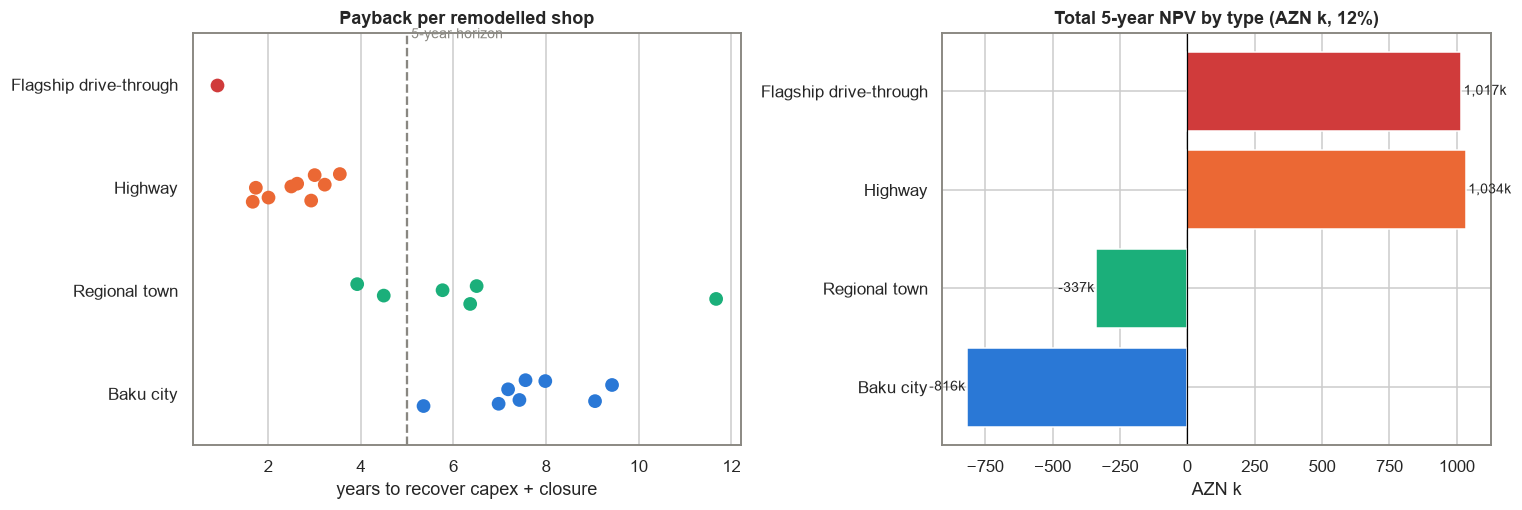

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
order = ["Flagship drive-through", "Highway", "Regional town", "Baku city"]
colmap = {"Flagship drive-through": RED, **TCOL}
sns.stripplot(data=roi, x="payback (years)", y="type", order=order, palette=colmap, size=9, ax=ax[0], jitter=.15)
ax[0].axvline(YEARS, color=GREY, ls="--"); ax[0].text(YEARS, -0.45, " 5-year horizon", color=GREY, fontsize=9)
ax[0].set(title="Payback per remodelled shop", ylabel="", xlabel="years to recover capex + closure")
nv_ = roi.groupby("type")["5-yr NPV"].sum().reindex(order) / 1e3
ax[1].barh(order[::-1], nv_.values[::-1], color=[colmap[o] for o in order[::-1]])
for i, v in enumerate(nv_.values[::-1]): ax[1].text(v + (8 if v >= 0 else -8), i, f"{v:,.0f}k", va="center", ha="left" if v >= 0 else "right", fontsize=9)
ax[1].axvline(0, color="black", lw=.8); ax[1].set(title="Total 5-year NPV by type (AZN k, 12%)", xlabel="AZN k")
plt.tight_layout(); plt.savefig("images/roi_by_type.png", dpi=120, bbox_inches="tight"); plt.show()

### Where to go next: wave-4 candidates

In [18]:
cand = st[st.remodel_date.isna()].copy()
pre_all = p[(p.week_start >= p.week_start.max() - pd.Timedelta(weeks=52))].groupby("station_id").revenue_azn.mean()
cand["weekly_rev"] = cand.station_id.map(pre_all)
cand["capex_est"] = cand.location_type.map(roi.groupby("type").capex.mean())
cand["eff"] = cand.location_type.map(het["steady-state effect"])
cand["annual_gm_gain"] = cand.weekly_rev * (np.exp(cand.eff) - 1) * 52 * GM_INC
cand["payback_years"] = (cand.capex_est + 2 * cand.weekly_rev * GM_BASE) / cand.annual_gm_gain
cand["npv_5y"] = -cand.capex_est - 2 * cand.weekly_rev * GM_BASE + sum(cand.annual_gm_gain / (1 + R_DISC) ** y for y in range(1, YEARS + 1))
cand = cand.sort_values("npv_5y", ascending=False)
print("Shops with positive 5-year NPV:", (cand.npv_5y > 0).sum(), "of", len(cand))
cand[["station_id", "location_type", "area", "weekly_rev", "annual_gm_gain", "payback_years", "npv_5y"]].head(10).round({"weekly_rev": 0, "annual_gm_gain": 0, "payback_years": 1, "npv_5y": 0})

Shops with positive 5-year NPV: 4 of 36


,station_id,location_type,area,weekly_rev,annual_gm_gain,payback_years,npv_5y
40,ST-41,Highway,Baku-Alat M3,"37,423.000","130,911.000",1.800,"231,838.000"
30,ST-31,Highway,Baku-Alat M3,"28,874.000","101,004.000",2.300,"128,818.000"
35,ST-36,Highway,Ganja-Gazakh M2,"28,204.000","98,663.000",2.400,"120,753.000"
33,ST-34,Highway,Baku-Alat M3,"24,459.000","85,559.000",2.700,"75,614.000"
32,ST-33,Highway,Ganja-Gazakh M2,"17,661.000","61,780.000",3.700,"-6,298.000"
54,ST-55,Regional town,Quba,"16,654.000","26,082.000",6.000,"-61,305.000"
58,ST-59,Regional town,Shirvan,"13,699.000","21,455.000",7.200,"-76,332.000"
52,ST-53,Regional town,Mingachevir,"13,205.000","20,682.000",7.400,"-78,841.000"
22,ST-23,Baku city,Narimanov,"28,028.000","33,776.000",6.000,"-79,564.000"
49,ST-50,Regional town,Gabala,"12,826.000","20,088.000",7.600,"-80,769.000"


Only **4 of the 36** shops that are still on the old format pay back the full remodel within 5 years: ST-41, ST-31, ST-36 and ST-34, all on highways. For regional and city shops the uplift is real but too small for a AZN 150–185k remodel; they need a cheaper format.

**Keep a control group.** The five old-format highway shops are the only clean controls for highway remodels. If all of them are remodelled, the next initiative on highways cannot be measured. ST-33 has a slightly negative NPV and should stay on the old format as a holdout.

**Accuracy of the AZN figure:** the incremental revenue to date (AZN 5.50 M) is about 12% above the true AZN 4.89 M, consistent with the overall estimate being slightly high (0.119 vs 0.109, inside the CI). Present it as a range, roughly AZN 4.5–6.5 M.

## 10. Findings & recommendations

In [19]:
ct, hw, rg = het["steady-state effect"]
f = pd.DataFrame([
 ["Overall effect", f"+{(np.exp(ATT)-1)*100:.1f}% revenue (95% CI {(np.exp(lo[0])-1)*100:.1f}–{(np.exp(hi[0])-1)*100:.1f}%); true effect +{(np.exp(TRUE_ATT)-1)*100:.1f}%; AZN {np.nansum(inc)/1e6:.2f} M extra revenue to date",
  "Report this number to the board, not the dashboard's 'remodelled vs not' gap, which is several times too high"],
 ["Method", f"Before/after {est.estimate.iloc[0]:+.3f}, remodelled-vs-not {est.estimate.iloc[1]:+.3f}, TWFE type×week {tw2[0]:+.3f}, stratified DiD {ATT:+.3f} vs truth {TRUE_ATT:+.3f}",
  "Evaluate every store initiative with never-treated controls of the same location type, plus an event study"],
 ["Ramp-up", "The effect builds over the first 10–15 weeks, then levels off", "Do not judge a remodel before week 16; set a 20-week review gate"],
 ["Location", f"Steady-state uplift: Highway +{(np.exp(hw)-1)*100:.0f}%, Regional +{(np.exp(rg)-1)*100:.0f}%, Baku city +{(np.exp(ct)-1)*100:.0f}%" ,
  "Wave 4 = the 4 old-format highway shops with positive 5-yr NPV (ST-41, ST-31, ST-36, ST-34)"],
 ["Payback", "Median payback: " + "; ".join(f"{t}: {roi_t.loc[t,'payback_years']:.1f} y" for t in order) + f". 5-yr NPV positive for {roi_t.loc['Highway','npv_positive']} highway, {roi_t.loc['Regional town','npv_positive']} regional, {roi_t.loc['Baku city','npv_positive']} city shops",
  "Stop the full remodel for city and regional shops; test a cheaper 'coffee corner' format (target capex under AZN 60k)"],
 ["Measurement", "The 5 old-format highway shops are the only clean highway controls", "Keep ST-33 on the old format as a permanent holdout"],
 ["Drive-through", f"ST-45: +{(np.exp(fl_eff)-1)*100:.0f}% (synthetic control, permutation p = {p_val:.3f}), about twice a normal highway remodel",
  "Pilot drive-through lanes at 2–3 more high-traffic highway stations, with a synthetic-control read-out"],
 ["Mechanism", f"{dec.iloc[1,1]*100:.0f}% of the uplift from more transactions, {dec.iloc[2,1]*100:.0f}% from bigger baskets", "Track footfall and attach rate (coffee + food) as leading KPIs after reopening"],
], columns=["Area", "Evidence", "Recommendation"])
f.style.hide(axis="index").set_properties(**{"text-align": "left", "white-space": "pre-wrap"})

Area,Evidence,Recommendation
Overall effect,+12.6% revenue (95% CI 10.3–15.2%); true effect +11.5%; AZN 5.50 M extra revenue to date,"Report this number to the board, not the dashboard's 'remodelled vs not' gap, which is several times too high"
Method,"Before/after +0.139, remodelled-vs-not +0.498, TWFE type×week +0.096, stratified DiD +0.119 vs truth +0.109","Evaluate every store initiative with never-treated controls of the same location type, plus an event study"
Ramp-up,"The effect builds over the first 10–15 weeks, then levels off",Do not judge a remodel before week 16; set a 20-week review gate
Location,"Steady-state uplift: Highway +19%, Regional +9%, Baku city +7%","Wave 4 = the 4 old-format highway shops with positive 5-yr NPV (ST-41, ST-31, ST-36, ST-34)"
Payback,"Median payback: Flagship drive-through: 0.9 y; Highway: 2.6 y; Regional town: 6.1 y; Baku city: 7.5 y. 5-yr NPV positive for 9/9 highway, 0/6 regional, 0/8 city shops",Stop the full remodel for city and regional shops; test a cheaper 'coffee corner' format (target capex under AZN 60k)
Measurement,The 5 old-format highway shops are the only clean highway controls,Keep ST-33 on the old format as a permanent holdout
Drive-through,"ST-45: +31% (synthetic control, permutation p = 0.027), about twice a normal highway remodel","Pilot drive-through lanes at 2–3 more high-traffic highway stations, with a synthetic-control read-out"
Mechanism,"65% of the uplift from more transactions, 35% from bigger baskets",Track footfall and attach rate (coffee + food) as leading KPIs after reopening
